# 04 · The heat equation in every form

The heat equation is the model parabolic problem, and its variants cover most of what engineering conduction
asks: fixed, insulated or convective surfaces, periodic heating, layered materials, cylinders and spheres, and
fins. Each has an exact solution, which makes it the ideal place to practise the discipline of the course:
separate the spatial and temporal errors, measure the orders, check conservation. This notebook runs through
the library's heat problems with those checks.

**What you will learn**
- solve the heat equation with every boundary type and check it against exact solutions
- run a space-time convergence study and read the two orders from it
- handle layered materials and radial geometry
- integrate a stiff engineering problem with large implicit steps

**Before you start:** notebooks 01 and 02  ·  **Time:** about 60 min

In [1]:
try:                      # on Google Colab (or anywhere engmolines is missing): install it from GitHub
    import engmolines
except ImportError:
    import subprocess, sys
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "git+https://github.com/ktwyw/engmolines"], check=True)
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from engmolines import problems as pr, integrators as ti, analysis, stiffness
plt.rcParams.update({"figure.figsize": (7, 4), "figure.dpi": 90, "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})

import inspect
from IPython.display import Code

def show_source(obj):
    """Display the source code of a library function or class."""
    return Code(inspect.getsource(obj), language="python")

def heading(text):
    print(f"\n{text}\n" + "=" * len(text))

## Boundary conditions: Dirichlet, Neumann, Robin, time-dependent

In [2]:
for make in (pr.heat_dirichlet, pr.heat_neumann, pr.heat_robin, pr.heat_time_dependent):
    p = make()
    s = p.solve("bdf", 1e-3 if make is not pr.heat_time_dependent else 5e-3, order=4)
    print(f"{p.name:<36}: error vs exact {p.error(s):.2e}; {p.notes}")
p = pr.heat_neumann(); s = p.solve("bdf", 1e-3, order=2, n_out=5)
print(f"\ninsulated ends: the integral of u changes by {np.ptp(analysis.conservation(p.grid, s.y)):.1e} - the Neumann ghosts are conservative")
p = pr.heat_robin()
print(f"convective ends with Bi = {p.params['Bi']}: first eigenvalue mu = {p.params['mu']:.5f} from mu tan(mu/2) = Bi")

heat, Dirichlet ends                : error vs exact 1.41e-04; the model problem: one Fourier mode decaying
heat, insulated ends                : error vs exact 1.41e-04; Neumann ghosts conserve the integral


heat, convective (Robin) ends       : error vs exact 4.64e-05; Biot number sets the eigenvalue


heat, periodically heated boundary  : error vs exact 2.75e-04; penetration depth 1/k; the wave lags by k x

insulated ends: the integral of u changes by 1.9e-16 - the Neumann ghosts are conservative
convective ends with Bi = 2.0: first eigenvalue mu = 1.72067 from mu tan(mu/2) = Bi


All four solve to the accuracy of the spatial grid (10⁻⁴), with the time error below it at BDF4 and h = 10⁻³.
The Neumann problem conserves the heat content because the ghost formula makes the boundary flux exactly
zero; the Robin problem's decay rate comes from the transcendental equation μ tan(μ/2) = Bi that couples the
Biot number to the eigenvalue - a result the numerical solution reproduces without knowing it.

## Separating the errors: a space-time convergence table

In [3]:
def run(n, h):
    p = pr.heat_dirichlet(n=n)
    s = p.solve("bdf", h, order=2)
    return p.x, s.y[-1]
p = pr.heat_dirichlet()
study = analysis.convergence_study(run, [10, 20, 40, 80], [0.02, 0.01, 0.005, 0.0025], lambda x: p.exact(x, 0.2))
print(pd.DataFrame(study["errors"], index=[f"n = {n}" for n in (10, 20, 40, 80)], columns=[f"h = {h}" for h in (0.02, 0.01, 0.005, 0.0025)]).to_string(float_format="%.2e"))
print("orders along the finest time step (space):", np.round(study["space_orders"], 2), "  along the finest grid (time):", np.round(study["time_orders"], 2))

        h = 0.02  h = 0.01  h = 0.005  h = 0.0025
n = 10  1.23e-03  1.39e-03   2.05e-03    2.21e-03
n = 20  2.96e-03  3.22e-04   3.43e-04    5.09e-04
n = 40  3.39e-03  7.47e-04   8.13e-05    8.54e-05
n = 80  3.49e-03  8.53e-04   1.87e-04    2.04e-05
orders along the finest time step (space): [2.12 2.58 2.07]   along the finest grid (time): [2.03 2.19 3.2 ]


Isolating each error: BDF4 at a tiny step for the spatial order, and the exact semi-discrete solution for the time order.

In [4]:
from engmolines import stencils as st
e_space = [pr.heat_dirichlet(n=n).error(pr.heat_dirichlet(n=n).solve("bdf", 2e-4, order=4)) for n in (10, 20, 40, 80)]
p40 = pr.heat_dirichlet(n=40)
A = st.diff_operator(p40.x, 2, 2).to_dense(); A[0, :] = A[-1, :] = 0.0
ref = ti.exponential(A, p40.y0, (0, 0.2)).y[-1]
e_time = [np.max(np.abs(p40.solve("bdf", h, order=2).y[-1] - ref)) for h in (0.02, 0.01, 0.005, 0.0025)]
print("spatial orders (time error negligible):", np.round(analysis.observed_order(e_space), 2))
print("temporal orders (against the exact semi-discrete solution):", np.round(analysis.observed_order(e_time), 2))

spatial orders (time error negligible): [2.01 2.   2.  ]
temporal orders (against the exact semi-discrete solution): [1.99 2.   2.  ]


Along a row the time error falls fourfold per halving of h (BDF2) until it meets the spatial floor; down a
column the spatial error falls fourfold per doubling of n until the time error takes over - and where the two
are comparable they can *cancel*: in the n = 10 row the error grows as h shrinks, because the time error had
been compensating part of the spatial one. Mixed tables are therefore read only where one error dominates;
the clean measurement of each order isolates it, as the next cell does.

## Layers, cylinders, spheres

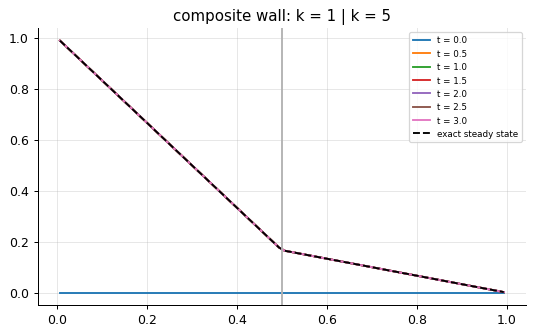

steady-state error 2.2e-16; heat flux q = 1.6667 = (T_L - T_R) / (L1/k1 + L2/k2)
cooling cylinder  : first-mode decay exact to 5.6e-05 (the r = 0 control volume: no singularity)


cooling sphere    : first-mode decay exact to 7.4e-05 (the r = 0 control volume: no singularity)


In [5]:
p = pr.composite_wall(); s = p.solve("bdf", 0.0075, order=2, n_out=6)
for t, y in zip(s.t, s.y):
    plt.plot(p.x, y, label=f"t = {t:.1f}")
plt.plot(p.x, p.exact(p.x), "k--", label="exact steady state"); plt.axvline(0.5, color="0.7"); plt.legend(fontsize=7); plt.title("composite wall: k = 1 | k = 5"); plt.show()
print(f"steady-state error {np.max(np.abs(s.y[-1] - p.exact(p.x))):.1e}; heat flux q = {p.params['q']:.4f} = (T_L - T_R) / (L1/k1 + L2/k2)")
for make in (pr.cooling_cylinder, pr.cooling_sphere):
    p = make(); s = p.solve("bdf", 1e-3, order=4)
    print(f"{p.name:<18}: first-mode decay exact to {p.error(s):.1e} (the r = 0 control volume: no singularity)")

The composite wall reaches the series-resistance steady state exactly because harmonic face averaging makes
the flux continuous across the interface. The cylinder's and sphere's first modes - a Bessel function and
sin(πr)/(πr) - decay at their exact rates; at r = 0 the operator uses the control-volume form (2(p + 1)κ(u₁ −
u₀)/Δr² at the axis) rather than the singular 1/r.

## A fin heating up: stiff, with a known steady state

eigenvalues from -82.3 to -0.0274 1/s: ratio 3007; RK4 limit 0.034 s


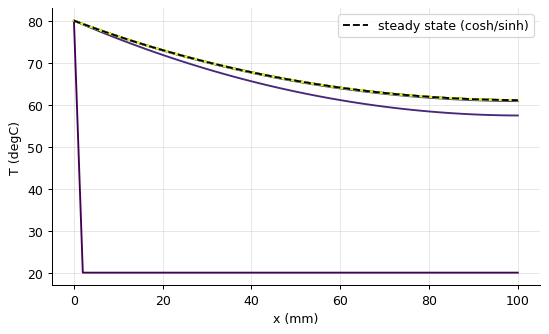

BDF2 with 2 s steps (450 steps, 1 Jacobian): steady-state error 4.0e-04 K; time constant 1/beta = 146 s


In [6]:
p = pr.fin_transient()
lam = stiffness.spectrum(p.rhs, p.y0, band=(1, 1)); lam = lam[np.abs(lam) > 1e-9]
print(f"eigenvalues from {lam[0].real:.1f} to {lam[-1].real:.4f} 1/s: ratio {stiffness.stiffness_ratio(lam):.0f}; RK4 limit {stiffness.explicit_step_limit(lam, 'rk4'):.3f} s")
s = p.solve("bdf", 2.0, order=2, n_out=9)
for t, y in zip(s.t, s.y):
    plt.plot(p.x * 1000, y, color=plt.cm.viridis(t / s.t[-1]))
plt.plot(p.x * 1000, p.exact(p.x), "k--", label="steady state (cosh/sinh)"); plt.xlabel("x (mm)"); plt.ylabel("T (degC)"); plt.legend(); plt.show()
print(f"BDF2 with 2 s steps ({s.steps} steps, {s.jacobian_evaluations} Jacobian): steady-state error {np.max(np.abs(s.y[-1] - p.exact(p.x))):.1e} K; time constant 1/beta = {p.params['time_constant']:.0f} s")

The fin's semi-discrete system has eigenvalues from −82 s⁻¹ (the grid modes) to −0.03 s⁻¹ (the fin's own
time constant of about 30 s): explicit RK4 could take steps of 0.034 s, BDF2 takes 2 s - sixty times larger -
and reaches the classical cosh/sinh steady state. The problem is the project of the companion course
`engnumeric`, solved there by hand; here it is one line.

## Inside the algorithm: the Robin eigenvalue

In [7]:
from scipy.optimize import brentq
Bi = 2.0
mu = brentq(lambda m: m * np.tan(m / 2) - Bi, 1e-6, np.pi - 1e-6)
p = pr.heat_robin(); s = p.solve("bdf", 1e-3, order=4)
rate = -np.log(s.y[-1][20] / p.y0[20]) / s.t[-1]
print(f"measured decay rate {rate:.5f} vs mu^2 = {mu**2:.5f}")

measured decay rate 2.96078 vs mu^2 = 2.96070


## Exercises
1. The periodically heated slab has penetration depth 1/k with k = sqrt(omega / 2 kappa). Solve it on a domain of length 2/k and of length 8/k with the far boundary insulated instead of imposed; how does the far-boundary choice affect the solution near x = 0, and at what domain length does it stop mattering?
2. Make the composite wall's second layer ten times more conductive and a tenth as thick (equal resistance). Confirm the same steady flux, and compare the time to reach 95 % of it.
3. **Implement it yourself:** write the cylindrical diffusion operator with the control-volume treatment at r = 0 and reproduce the cooling-cylinder decay rate.